# 📊 Análisis Exploratorio de Datos (EDA) — Clasificación Semántica Zero-Shot / Prototípica (2010–2023)

Este notebook realiza la **auditoría y exploración del conjunto de datos procesado (capa Silver)** resultante del pipeline de categorización semántica y filtrado de ruido (`src/articulos/etl_categorizacion.py`):
- **Origen en Data Lake (Cloudflare R2 / S3):** `processed/huggingface/multisource_bancos_2010_2023.parquet`.
- **Universo de estudio:** Los 6 grandes bancos de EE. UU. (**US Big 6**: `JPM`, `BAC`, `WFC`, `C`, `GS`, `MS`).
- **Modelo de clasificación aplicado:** Bi-Encoder `sentence-transformers/all-MiniLM-L6-v2` con centroides prototípicos, extracción guiada de fragmentos (`process_text`), desambiguación de rol de analista y umbrales adaptativos.

### Objetivos del EDA:
1. **Inspección Estructural y Esquema Silver:** Verificar dimensiones, tipos de datos, ausencia de nulos críticos y poda de columnas crudas.
2. **Balance Señal vs. Ruido (`is_ruido`):** Cuantificar la proporción de noticias financieras relevantes frente al ruido descartado globalmente y por entidad bancaria.
3. **Distribución de Categorías Temáticas (`category`) y Confianza (`confianza`):** Evaluar el reparto entre *Earnings*, *M&A*, *Macro*, *Legal*, *Credit*, *Governance* y *Ruido*, así como la distribución estadística del score de similitud coseno.
4. **Cobertura Temporal Post-Filtrado (2010–2023):** Comprobar la densidad anual de noticias limpias por banco tras descartar el ruido para garantizar series continuas hacia la fase de sentimiento con **FinBERT**.

In [5]:
# 1. Configuración del entorno y carga del dataset categorizado (Capa Silver) desde S3/R2 o backup local

import sys
from pathlib import Path
import pandas as pd
import numpy as np
import pyarrow.parquet as pq
import pyarrow.fs as fs
from IPython.display import display

# Resolver ruta hacia 'src' para importar módulos de configuración del proyecto
CURRENT_DIR = Path.cwd().resolve()
SRC_PATH = str(CURRENT_DIR.parent) if CURRENT_DIR.name == "notebooks" else str(CURRENT_DIR / "src")
if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)

from config.settings import settings

# Columnas esperadas en el dataset procesado (capa Silver)
COLS = [
    "ticker", "company_name", "cik", "date", "datetime",
    "title", "article", "ticker_count", "is_multisubject",
    "process_text", "category", "confianza", "is_ruido"
]

def cargar_parquet_lazy() -> pd.DataFrame:
    """Descarga y carga el dataset categorizado desde Cloudflare R2 / S3 (o backup local si existe)."""
    # Comprobar primero si existe el backup local generado por etl_categorizacion.py
    local_candidates = [
        Path("data/processed_multisource_bancos_2010_2023.parquet"),
        Path("../../data/processed_multisource_bancos_2010_2023.parquet"),
        Path("../data/processed_multisource_bancos_2010_2023.parquet"),
    ]
    ruta_local = next((p for p in local_candidates if p.exists()), None)

    if ruta_local:
        print(f"Cargando dataset local desde [{ruta_local}]...")
        return pd.read_parquet(ruta_local, columns=COLS)

    # Configurar el sistema de archivos S3 utilizando las credenciales de settings
    s3_fs = fs.S3FileSystem(
        access_key=settings.aws_access_key_id,
        secret_key=settings.aws_secret_access_key,
        endpoint_override=settings.s3_endpoint_url,
        region=settings.s3_region
    )

    file_path = f"{settings.s3_bucket_name}/processed/huggingface/multisource_bancos_2010_2023.parquet"

    print(f"Leyendo metadatos y dataset desde S3/R2 [{file_path}] con PyArrow S3FileSystem...")
    table = pq.read_table(file_path, filesystem=s3_fs, columns=COLS)
    return table.to_pandas()

# Ejecutar la carga y mostrar diagnóstico inicial
df = cargar_parquet_lazy()
print(f"Dataset cargado exitosamente: {df.shape[0]:,} registros x {df.shape[1]} columnas.")
display(df.head())

Leyendo metadatos y dataset con PyArrow S3FileSystem...
  ticker               company_name            cik                 date  \
0    BAC  Bank of America Corp /DE/  CIK0000070858  2010-01-02 02:16:00   
1    JPM       JPMorgan Chase & Co.  CIK0000019617  2010-01-02 02:16:00   
2    WFC   Wells Fargo & Company/MN  CIK0000072971  2010-01-02 02:16:00   
3     GS   Goldman Sachs Group Inc.  CIK0000886982  2010-01-02 12:45:00   
4    JPM       JPMorgan Chase & Co.  CIK0000019617  2010-01-02 12:45:00   

                   datetime                                             title  \
0 2010-01-02 02:16:00+00:00  Stocks may struggle with less government support   
1 2010-01-02 02:16:00+00:00  Stocks may struggle with less government support   
2 2010-01-02 02:16:00+00:00  Stocks may struggle with less government support   
3 2010-01-02 12:45:00+00:00                                           Preview   
4 2010-01-02 12:45:00+00:00                   How to Bet on Health and Wealth   

      

---
## 1. Normalización Temporal y Balance Global: Datos que Sirven (`is_ruido == False`) vs. Datos que No Sirven (`is_ruido == True`)

En esta celda realizamos tres tareas fundamentales antes de construir las matrices de cobertura:
1. **Estandarización de Fechas:** Convertimos la columna `datetime` a formato `UTC` y extraemos el año (`year`) acotando estrictamente la ventana de estudio **2010–2023**.
2. **Partición Señal vs. Ruido:** Dividimos el dataset en dos subconjuntos disjuntos según la decisión del clasificador semántico:
   - `df_util` (`is_ruido == False`): Noticias con señal financiera legítima que alimentarán a **FinBERT**.
   - `df_ruido` (`is_ruido == True`): Noticias descartadas (rol de analista sobre terceros, ticker bleed sin saliencia de entidad, baja confianza semántica o temática fuera de dominio).
3. **Tabla de Balance por Banco:** Cuantificamos cuántas noticias útiles y cuántas de ruido tiene cada uno de los 6 bancos (`BAC`, `C`, `GS`, `JPM`, `MS`, `WFC`), junto con su tasa de retención (`% Útil`).

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estética general para los gráficos del EDA
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.figsize": (12, 6), "font.size": 11})

# 1. Normalización de la columna temporal y extracción del año
df["dt_parsed"] = pd.to_datetime(df["datetime"], utc=True, errors="coerce")
nulos_fecha = df["dt_parsed"].isna().sum()
print(f"Nulos en fecha tras parseo UTC: {nulos_fecha:,}")

df_valid = df.dropna(subset=["dt_parsed"]).copy()
df_valid["year"] = df_valid["dt_parsed"].dt.year

# Filtrar estrictamente al horizonte del TFM (2010-2023)
df_2010_2023 = df_valid[(df_valid["year"] >= 2010) & (df_valid["year"] <= 2023)].copy()

# 2. Separar los datos que SIRVEN (is_ruido == False) de los que NO SIRVEN (is_ruido == True)
df_util = df_2010_2023[~df_2010_2023["is_ruido"]].copy()
df_ruido = df_2010_2023[df_2010_2023["is_ruido"]].copy()

total_noticias = len(df_2010_2023)
print("=" * 75)
print(f"RESUMEN GLOBAL EN VENTANA 2010-2023: {total_noticias:,} noticias")
print("-" * 75)
print(f"✔ Datos que SIRVEN (Señal / is_ruido=False) : {len(df_util):>7,} ({len(df_util) / total_noticias * 100:.2f}%)")
print(f"✖ Datos que NO SIRVEN (Ruido / is_ruido=True): {len(df_ruido):>7,} ({len(df_ruido) / total_noticias * 100:.2f}%)")
print("=" * 75)

# 3. Resumen desglosado por entidad bancaria
balance_bancos = (
    df_2010_2023.groupby("ticker")
    .agg(
        Banco=("company_name", "first"),
        Total_Noticias=("title", "count"),
        Noticias_Utiles=("is_ruido", lambda s: int((~s).sum())),
        Noticias_Ruido=("is_ruido", lambda s: int(s.sum())),
        Confianza_Media_Util=("confianza", lambda s: round(s[~df_2010_2023.loc[s.index, "is_ruido"]].mean(), 2))
    )
    .reset_index()
)
balance_bancos["% Señal Útil"] = ((balance_bancos["Noticias_Utiles"] / balance_bancos["Total_Noticias"]) * 100).round(2)
balance_bancos["% Ruido"] = ((balance_bancos["Noticias_Ruido"] / balance_bancos["Total_Noticias"]) * 100).round(2)
balance_bancos = balance_bancos.sort_values(by="Noticias_Utiles", ascending=False).reset_index(drop=True)

display(balance_bancos)

Nulos en fecha tras parseo UTC: 0
RESUMEN GLOBAL EN VENTANA 2010-2023: 89,846 noticias
---------------------------------------------------------------------------
✔ Datos que SIRVEN (Señal / is_ruido=False) :  37,359 (41.58%)
✖ Datos que NO SIRVEN (Ruido / is_ruido=True):  52,487 (58.42%)


,ticker,Banco,Total_Noticias,Noticias_Utiles,Noticias_Ruido,Confianza_Media_Util,% Señal Útil,% Ruido
0,WFC,Wells Fargo & Company/MN,16075,7464,8611,48.62,46.43,53.57
1,MS,Morgan Stanley,16341,7084,9257,46.89,43.35,56.65
2,JPM,JPMorgan Chase & Co.,18953,6710,12243,47.15,35.40,64.60
3,GS,Goldman Sachs Group Inc.,18321,6708,11613,48.23,36.61,63.39
4,C,Citigroup Inc.,8647,5098,3549,49.91,58.96,41.04
5,BAC,Bank of America Corp /DE/,11509,4295,7214,47.61,37.32,62.68


---
## 2. Mapa de Calor y Diagnóstico de Cobertura de los Datos que SIRVEN (`is_ruido == False`)

En esta celda auditamos la cobertura temporal (2010–2023) **únicamente con las noticias útiles (`df_util`)**:
1. **Matriz Año × Banco (`pivot_util`):** Contabiliza el número exacto de noticias financieras válidas por año para cada ticker.
2. **Diagnóstico de Años Faltantes o de Baja Densidad:** Siguiendo la metodología de `huggingface_2010_2023_EDA_v2.ipynb`, verificamos automáticamente si algún banco quedó con **0 noticias** en algún año tras el filtrado o si presenta años con baja densidad muestral (`< 100` noticias/año).
3. **Mapa de Calor de Datos que Sirven:** Representa visualmente con una paleta verde-azulada (`YlGnBu`) el volumen anual de noticias válidas para identificar de un vistazo qué años y bancos tienen menor cobertura.

COBERTURA ANUAL DE DATOS QUE SIRVEN (SEÑAL FINANCIERA: is_ruido == False)


ticker,BAC,C,GS,JPM,MS,WFC,Total_Año
year,,,,,,,
2010,309,96,383,481,601,124,1994
2011,424,124,132,542,582,122,1926
2012,369,95,133,700,577,302,2176
2013,221,118,213,552,438,288,1830
2014,242,162,112,327,438,208,1489
2015,444,530,94,314,482,205,2069
2016,514,662,406,436,456,996,3470
2017,400,776,478,318,443,962,3377
2018,304,658,439,535,387,750,3073



DIAGNÓSTICO DE COBERTURA Y AÑOS FALTANTES / DÉBILES (DATOS ÚTILES)


,Banco,Total Noticias Útiles,Media Anual,Año Mínimo (Volumen),Años Cubiertos (de 14),Años con 0 Noticias,Años Débiles (<100 noticias)
0,BAC,4295,306.8,2021 (36),14,Ninguno,"[2021, 2022]"
1,C,5098,364.1,2021 (29),14,Ninguno,"[2010, 2012, 2021]"
2,GS,6708,479.1,2015 (94),14,Ninguno,[2015]
3,JPM,6710,479.3,2022 (24),14,Ninguno,"[2021, 2022]"
4,MS,7084,506.0,2019 (379),14,Ninguno,Ninguno
5,WFC,7464,533.1,2011 (122),14,Ninguno,Ninguno


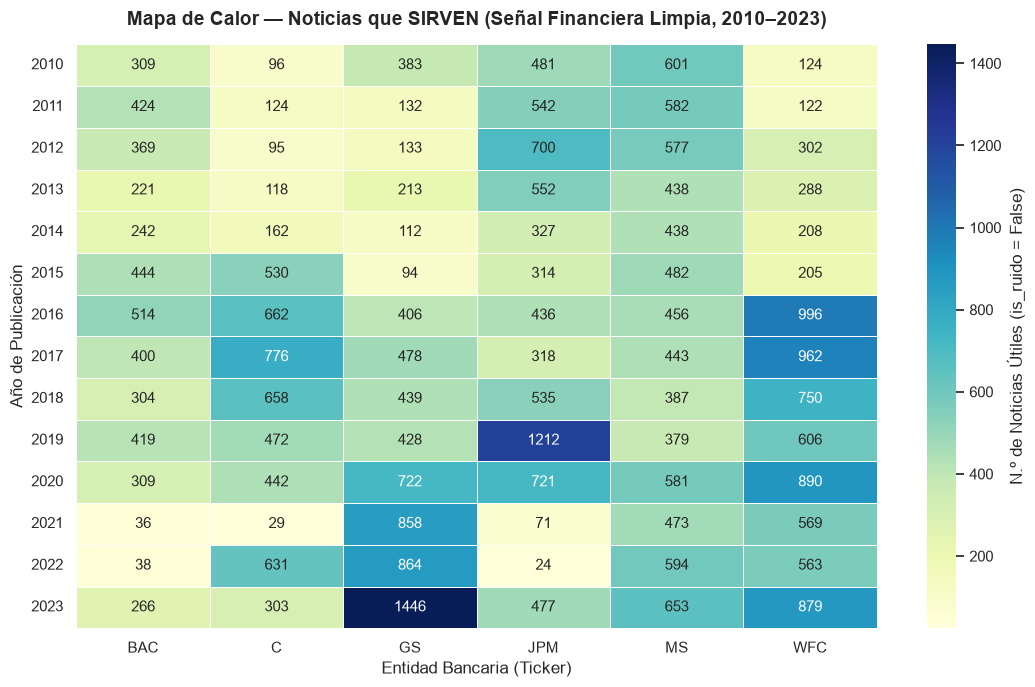

In [7]:
# 1. Construir matriz pivote de noticias ÚTILES (is_ruido == False) por Año y Banco
BANCOS = ["BAC", "C", "GS", "JPM", "MS", "WFC"]
ANIOS = range(2010, 2024)

pivot_util = pd.pivot_table(
    df_util,
    index="year",
    columns="ticker",
    values="title",
    aggfunc="count",
    fill_value=0
).reindex(index=ANIOS, columns=BANCOS, fill_value=0)

# Añadir fila y columna de totales para la tabla numérica
pivot_util_tabla = pivot_util.copy()
pivot_util_tabla["Total_Año"] = pivot_util_tabla.sum(axis=1)
pivot_util_tabla.loc["Total_Banco"] = pivot_util_tabla.sum(axis=0)

print("=" * 80)
print("COBERTURA ANUAL DE DATOS QUE SIRVEN (SEÑAL FINANCIERA: is_ruido == False)")
print("=" * 80)
display(pivot_util_tabla)

# 2. Diagnóstico automático de años faltantes (0 noticias) o débiles (< 100 noticias)
print("\n" + "=" * 80)
print("DIAGNÓSTICO DE COBERTURA Y AÑOS FALTANTES / DÉBILES (DATOS ÚTILES)")
print("=" * 80)

resumen_cobertura = []
for banco in BANCOS:
    serie_banco = pivot_util[banco]
    anios_cero = serie_banco[serie_banco == 0].index.tolist()
    anios_bajos = serie_banco[(serie_banco > 0) & (serie_banco < 100)].index.tolist()
    resumen_cobertura.append({
        "Banco": banco,
        "Total Noticias Útiles": int(serie_banco.sum()),
        "Media Anual": round(serie_banco.mean(), 1),
        "Año Mínimo (Volumen)": f"{serie_banco.idxmin()} ({int(serie_banco.min())})",
        "Años Cubiertos (de 14)": int((serie_banco > 0).sum()),
        "Años con 0 Noticias": anios_cero if anios_cero else "Ninguno",
        "Años Débiles (<100 noticias)": anios_bajos if anios_bajos else "Ninguno"
    })

display(pd.DataFrame(resumen_cobertura))

# 3. Mapa de calor de los datos que SIRVEN (is_ruido == False)
plt.figure(figsize=(11, 7))
ax = sns.heatmap(
    pivot_util,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "N.º de Noticias Útiles (is_ruido = False)"}
)
plt.title("Mapa de Calor — Noticias que SIRVEN (Señal Financiera Limpia, 2010–2023)", fontsize=14, weight="bold", pad=14)
plt.xlabel("Entidad Bancaria (Ticker)", fontsize=12)
plt.ylabel("Año de Publicación", fontsize=12)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

---
## 3. Mapa de Calor de los Datos que NO SIRVEN / Descartados (`is_ruido == True`)

En esta celda construimos la matriz y el mapa de calor equivalentes para el subconjunto **`df_ruido` (`is_ruido == True`)**:
1. **Matriz Año × Banco de Ruido (`pivot_ruido`):** Muestra cuántas noticias fueron filtradas por el clasificador semántico en cada año y banco.
2. **Mapa de Calor de Datos que No Sirven:** Utilizamos una paleta cálida/rojiza (`OrRd`) para visualizar en qué años y bancos se concentró la mayor cantidad de ruido descartado (por ejemplo, picos de notas de analistas emitidas por Goldman Sachs o Morgan Stanley, o menciones colaterales sin relevancia).
3. **Comparativa Visual Lado a Lado (% Retención):** Añadimos un segundo panel comparando directamente el mapa de calor de **Datos que Sirven** frente al de **Datos que No Sirven**.

VOLUMEN ANUAL DE DATOS QUE NO SIRVEN (RUIDO DESCARTADO: is_ruido == True)


ticker,BAC,C,GS,JPM,MS,WFC,Total_Año
year,,,,,,,
2010,1018,56,851,1235,1297,419,4876
2011,737,53,356,810,784,265,3005
2012,617,46,344,997,588,334,2926
2013,410,36,362,704,481,351,2344
2014,335,62,243,548,420,254,1862
2015,439,312,213,554,571,456,2545
2016,463,405,798,776,675,1531,4648
2017,663,503,1022,697,779,1279,4943
2018,431,458,816,909,696,674,3984


c:\Users\felip\OneDrive\Felipe\Master\TFM\TFM-Master\.venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 10004 (\N{HEAVY CHECK MARK}) missing from font(s) Arial.
  fig.canvas.draw()
C:\Users\felip\AppData\Local\Temp\ipykernel_3372\460727122.py:53: UserWarning: Glyph 10006 (\N{HEAVY MULTIPLICATION X}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\felip\OneDrive\Felipe\Master\TFM\TFM-Master\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10004 (\N{HEAVY CHECK MARK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\felip\OneDrive\Felipe\Master\TFM\TFM-Master\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10006 (\N{HEAVY MULTIPLICATION X}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


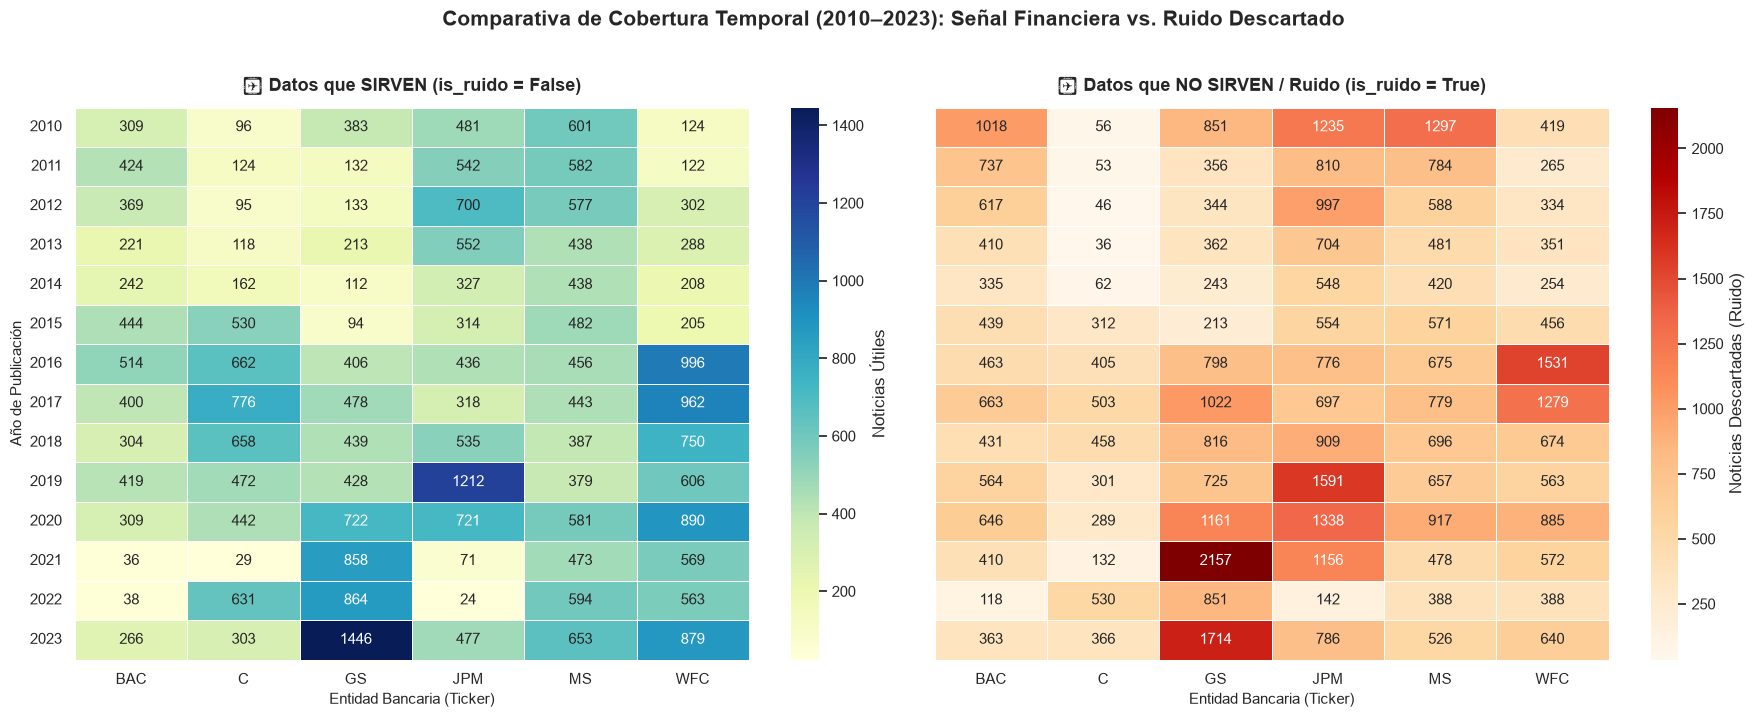

In [8]:
# 1. Construir matriz pivote de noticias que NO SIRVEN / RUIDO (is_ruido == True) por Año y Banco
pivot_ruido = pd.pivot_table(
    df_ruido,
    index="year",
    columns="ticker",
    values="title",
    aggfunc="count",
    fill_value=0
).reindex(index=ANIOS, columns=BANCOS, fill_value=0)

pivot_ruido_tabla = pivot_ruido.copy()
pivot_ruido_tabla["Total_Año"] = pivot_ruido_tabla.sum(axis=1)
pivot_ruido_tabla.loc["Total_Banco"] = pivot_ruido_tabla.sum(axis=0)

print("=" * 80)
print("VOLUMEN ANUAL DE DATOS QUE NO SIRVEN (RUIDO DESCARTADO: is_ruido == True)")
print("=" * 80)
display(pivot_ruido_tabla)

# 2. Visualización comparativa lado a lado: Mapa de Calor SIRVEN vs. NO SIRVEN
fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=True)

# Panel Izquierdo: Datos que SIRVEN
sns.heatmap(
    pivot_util,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Noticias Útiles"},
    ax=axes[0]
)
axes[0].set_title("✔ Datos que SIRVEN (is_ruido = False)", fontsize=13, weight="bold", pad=12)
axes[0].set_xlabel("Entidad Bancaria (Ticker)", fontsize=11)
axes[0].set_ylabel("Año de Publicación", fontsize=11)
axes[0].tick_params(axis="y", rotation=0)

# Panel Derecho: Datos que NO SIRVEN (Ruido)
sns.heatmap(
    pivot_ruido,
    annot=True,
    fmt="d",
    cmap="OrRd",
    linewidths=0.5,
    cbar_kws={"label": "Noticias Descartadas (Ruido)"},
    ax=axes[1]
)
axes[1].set_title("✖ Datos que NO SIRVEN / Ruido (is_ruido = True)", fontsize=13, weight="bold", pad=12)
axes[1].set_xlabel("Entidad Bancaria (Ticker)", fontsize=11)
axes[1].set_ylabel("")

plt.suptitle("Comparativa de Cobertura Temporal (2010–2023): Señal Financiera vs. Ruido Descartado", fontsize=15, weight="bold", y=1.02)
plt.tight_layout()
plt.show()

---
## 4. Distribución por Categoría Semántica (`category`) y Nivel de Confianza (`confianza`)

Por último, analizamos cómo se distribuyen las noticias que **sí sirven (`is_ruido == False`)** a través de las categorías temáticas del modelo (`earnings`, `m&a`, `macro`, `legal`, `credit`, `governance`):
1. **Tabla de Distribución por Categoría:** Volumen y porcentaje de cada factor fundamental dentro del conjunto limpio, junto con su confianza media.
2. **Mapa de Calor Categoría × Banco (Datos Útiles):** Permite verificar la especialización temática de cada entidad (por ejemplo, mayor peso de *M&A* y *Macro* en bancos de inversión como `GS` y `MS`, o *Earnings* y *Legal/Credit* en banca comercial como `JPM`, `BAC` y `WFC`).

=== DISTRIBUCIÓN TEMÁTICA DE LAS NOTICIAS QUE SIRVEN (is_ruido == False) ===


,category,Noticias_Utiles,Confianza_Media,Confianza_Mediana,Confianza_Min,Confianza_Max,% del Total Útil
0,m&a,12675,47.03,46.78,30.01,69.87,33.93
1,earnings,12373,49.48,48.98,30.04,75.45,33.12
2,macro,6023,46.84,46.33,30.03,76.84,16.12
3,legal,3796,48.68,48.34,30.04,76.86,10.16
4,credit,1482,50.18,50.34,31.24,70.76,3.97
5,governance,1010,43.90,43.10,30.05,66.83,2.70


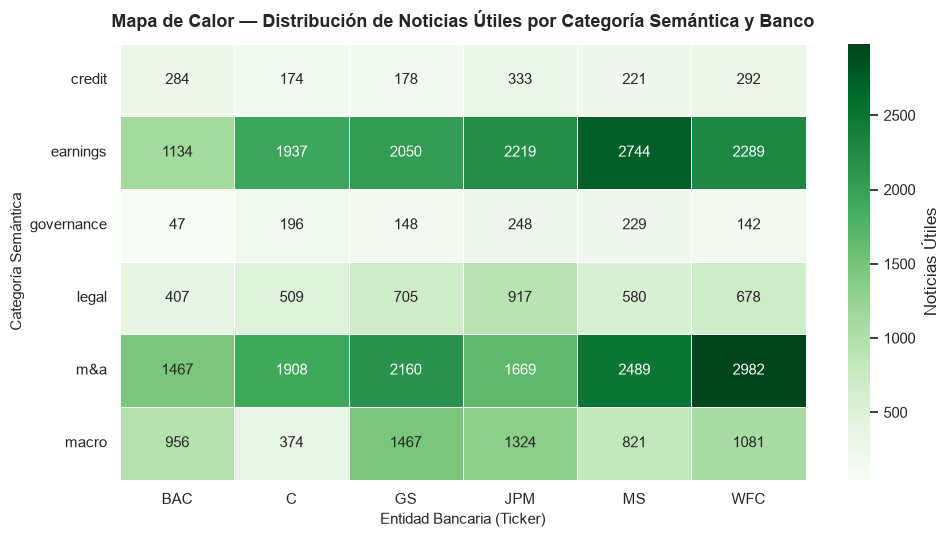

In [9]:
# 1. Resumen estadístico por categoría dentro de los datos que SIRVEN (df_util)
resumen_categorias = (
    df_util.groupby("category")
    .agg(
        Noticias_Utiles=("title", "count"),
        Confianza_Media=("confianza", "mean"),
        Confianza_Mediana=("confianza", "median"),
        Confianza_Min=("confianza", "min"),
        Confianza_Max=("confianza", "max")
    )
    .reset_index()
)
resumen_categorias["% del Total Útil"] = ((resumen_categorias["Noticias_Utiles"] / len(df_util)) * 100).round(2)
resumen_categorias[["Confianza_Media", "Confianza_Mediana", "Confianza_Min", "Confianza_Max"]] = (
    resumen_categorias[["Confianza_Media", "Confianza_Mediana", "Confianza_Min", "Confianza_Max"]].round(2)
)
resumen_categorias = resumen_categorias.sort_values(by="Noticias_Utiles", ascending=False).reset_index(drop=True)

print("=== DISTRIBUCIÓN TEMÁTICA DE LAS NOTICIAS QUE SIRVEN (is_ruido == False) ===")
display(resumen_categorias)

# 2. Mapa de calor de Categoría Semántica x Banco (solo noticias útiles)
pivot_cat_banco = pd.pivot_table(
    df_util,
    index="category",
    columns="ticker",
    values="title",
    aggfunc="count",
    fill_value=0
).reindex(columns=BANCOS, fill_value=0)

plt.figure(figsize=(10, 5.5))
sns.heatmap(
    pivot_cat_banco,
    annot=True,
    fmt="d",
    cmap="Greens",
    linewidths=0.5,
    cbar_kws={"label": "Noticias Útiles"}
)
plt.title("Mapa de Calor — Distribución de Noticias Útiles por Categoría Semántica y Banco", fontsize=13, weight="bold", pad=12)
plt.xlabel("Entidad Bancaria (Ticker)", fontsize=11)
plt.ylabel("Categoría Semántica", fontsize=11)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

---
## 5. Auditoría Cualitativa del Filtrado: Muestra Aleatoria de 5 Noticias por Banco

Para validar empíricamente que el clasificador semántico (`CategorizadorArticulos`) retiene verdadera señal financiera y descarta adecuadamente el ruido, extraemos una **muestra aleatoria estratificada de 5 noticias por cada uno de los 6 bancos** (`30` noticias en total):
1. **Muestra de Noticias que SÍ Sirven (`is_ruido == False`):** Permite comprobar que el titular (`title`), el fragmento extraído (`process_text`) y la categoría asignada (`category`) corresponden efectivamente a hechos relevantes del banco.
2. **Muestra de Noticias Descartadas como Ruido (`is_ruido == True`):** Permite verificar que los descartes corresponden a notas de analistas sobre terceros, menciones colaterales o baja relevancia semántica.

In [10]:
# Configurar pandas para mostrar el texto completo de los titulares y fragmentos sin truncar
pd.set_option("display.max_colwidth", None)

cols_muestra = ["date", "ticker", "category", "confianza", "is_ruido", "title", "process_text"]

# 1. Extraer 5 noticias aleatorias QUE SÍ SIRVEN (is_ruido == False) por cada banco
print("=" * 100)
print("✔ MUESTRA ALEATORIA: 5 NOTICIAS QUE SÍ SIRVEN (is_ruido == False) POR CADA BANCO")
print("=" * 100)

muestra_util_por_banco = (
    df_util.groupby("ticker", group_keys=False)
    .sample(n=5, random_state=42)[cols_muestra]
    .sort_values(["ticker", "date"])
    .reset_index(drop=True)
)
display(muestra_util_por_banco)

# 2. Extraer 5 noticias aleatorias QUE NO SIRVEN / RUIDO (is_ruido == True) por cada banco para contrastar
print("\n" + "=" * 100)
print("✖ MUESTRA ALEATORIA: 5 NOTICIAS DESCARTADAS COMO RUIDO (is_ruido == True) POR CADA BANCO")
print("=" * 100)

muestra_ruido_por_banco = (
    df_ruido.groupby("ticker", group_keys=False)
    .sample(n=5, random_state=42)[cols_muestra]
    .sort_values(["ticker", "date"])
    .reset_index(drop=True)
)
display(muestra_ruido_por_banco)

✔ MUESTRA ALEATORIA: 5 NOTICIAS QUE SÍ SIRVEN (is_ruido == False) POR CADA BANCO


,date,ticker,category,confianza,is_ruido,title,process_text
0,2010-07-19 15:55:00,BAC,macro,36.79,False,Citi: Moody's Raises Outlook to Stable,(Titular directo sin cuerpo)
1,2010-10-20 16:23:00,BAC,m&a,52.90,False,Hot Stocks: Regional Banks Slide,Regional banks Comerica and Marshall & Ilsley pressure the financial sector. Comerica drops more than 8% after CEO Ralph Babb says new loan growth won't pick up until confidence in the economy improves. MarketWatch's Alistair Barr reports.
2,2011-01-03 13:43:00,BAC,m&a,45.02,False,"Bank of America, Boeing, Borders in focus","U.S. stock futures trade higher on Monday, putting Wall Street firmly on track for a positive start to 2011, amid optimism about the outlook for U.S. growth."
3,2015-04-15 10:58:00,BAC,m&a,47.85,False,"Fast Money Picks For April 15: Bank Of America, Exxon Mobil, Intel",(Titular directo sin cuerpo)
4,2016-03-20 13:10:00,BAC,m&a,42.02,False,Bank of America Erroneously Declared Jim Chanos' $18M Mortgage Paid in Full -NY Post,(Titular directo sin cuerpo)
5,2017-05-12 00:00:00,C,legal,53.55,False,"Is Bank of America Really the ""Stingiest"" Big Bank?","k of America's annualized yield on total deposits was less than the other three megabanks: JPMorgan Chase (NYSE: JPM) , Wells Fargo (NYSE: WFC) , and Citigroup (NYSE: C) ."
6,2017-10-12 00:00:00,C,earnings,45.23,False,"Citi Reports Book Value Per Share of $78.81, Repurchased 81M Common Shares",(Titular directo sin cuerpo)
7,2017-11-03 00:00:00,C,m&a,44.71,False,"High Pointe Capital Management Llc Buys Progressive Corp, Micro Focus International PLC, Agrium ...","Citigroup Inc ( C ) - 27,520 shares, 2.93% of the total portfolio."
8,2018-06-20 14:30:00,C,legal,50.58,False,"'The auditor of Citi, Credit Suisse and Deutsche Bank was tipped off before regulatory inspection'",(Titular directo sin cuerpo)
9,2019-07-15 12:41:00,C,earnings,58.78,False,Citigroup Kicks Off Bank Earnings Season With a Strong Result,"The results set the stage for a busy week that will include reports from JPMorgan Chase, Wells Fargo, and Goldman Sachs."



✖ MUESTRA ALEATORIA: 5 NOTICIAS DESCARTADAS COMO RUIDO (is_ruido == True) POR CADA BANCO


,date,ticker,category,confianza,is_ruido,title,process_text
0,2010-03-04 21:33:00,BAC,legal,24.73,True,"Yes, Here Come the Fannie, Freddie Put-Backs",(Titular directo sin cuerpo)
1,2010-03-19 20:54:00,BAC,earnings,57.32,True,Financial shares stumble on weak profit outlook,U.S. financial shares are battered by a weak profit forecast from a major Wall Street firm.
2,2010-04-08 18:59:00,BAC,m&a,53.70,True,The Best in Big Banks,Credit Suisse says JPMorgan is best set to gain on better credit quality.
3,2012-10-24 19:51:00,BAC,ruido,34.26,True,Apple dominates one of the only two market sectors that matter now,"Apple Inc. is a bellwether for consumer demand and the health of the U.S. economy. But if consumer or banking stocks start to roll over, it's too late in the year for other sectors to support the Dow and the S&P 500."
4,2015-03-31 16:49:00,BAC,m&a,34.56,True,3 Bank Stocks Deutsche Bank Loves,(Titular directo sin cuerpo)
5,2010-04-26 21:01:00,C,macro,32.20,True,Citi slips as Treasury announces sale,"Citigroup Inc. leads a slide in in financial stocks, as the Treasury Department announces plans to sell up to 1.5 billion Citi shares."
6,2011-11-28 12:59:00,C,earnings,29.93,True,Citigroup shares add 5.1% in preopen,(Titular directo sin cuerpo)
7,2016-03-21 00:00:00,C,ruido,58.37,True,"Stock Market News for March 21, 2016","the S&P 500 sectors. Top holdings from the sector such as Wells Fargo & Company ( WFC ), American Express Company ( AXP ), Morgan Stanley ( MS ) and Citigroup Inc. ( C ) rose 1.6%, 1.9%, 1.7% and 1.6%, respectively."
8,2018-05-30 00:00:00,C,legal,33.84,True,Italy Turmoil Puts These 6 Bank Stocks at Risk,Turmoil in Italy: Citigroup (C)
9,2020-05-13 00:00:00,C,m&a,28.31,True,These Bonds Shouldn’t Be Available for “Individual Resale”,"By Brett Owens\naEURoeNot for individual resale.aEUR\nEver see that label on a box of food, and scratch your head? Like whoaEURtms buying this big-mega bag of Chips Ahoy for the purpose of reselling the aEURoeindividually packagedaEUR helpings of cookies inside?\nWhile you and I have better things to do than deconstruct groceries, we also have better ways to make money than deconstructing perfectly g"


---
### 5.1. Matriz de Auditoría Cualitativa (`random_state=42`, $N = 60$ noticias: 5 útiles y 5 de ruido por banco)

Tomando como **Clase Positiva** las noticias que **SÍ sirven (`is_ruido == False`)** y como **Clase Negativa** el **Ruido (`is_ruido == True`)**, la inspección manual de los 60 registros muestreados arroja el siguiente balance de calidad:

#### 📊 Resumen de la Matriz de Confusión Muestral ($N = 60$)

| Predicción del Clasificador \ Realidad Manual | Real: Útil (Señal Financiera del Banco) | Real: Ruido (Terceros / General / Sin Contexto) | Total Muestra | Métrica Muestral |
| :--- | :---: | :---: | :---: | :---: |
| **Predicho: SÍ Sirve (`is_ruido == False`)** | **TP = 18** | **FP = 12** | **30** (5 por banco) | **Precisión (PPV):** `60.0%` |
| **Predicho: Ruido (`is_ruido == True`)** | **FN = 5** | **TN = 25** | **30** (5 por banco) | **Valor Predictivo Negativo (NPV):** `83.3%` |
| **Total Real** | **23** | **37** | **60** | **Exactitud Global (Accuracy):** `71.7%` |

* **Sensibilidad (Recall sobre señal útil):** `78.3%` ($18 / 23$)
* **Especificidad (Tasa de rechazo de ruido real):** `67.6%` ($25 / 37$)

---

#### 🔍 A. Detalle de la Muestra `is_ruido == False` (18 TP vs. 12 FP)

| # | Ticker | Confianza | Categoría | Titular (`title`) | Evaluación | Justificación Técnica |
| :-: | :-: | :-: | :-: | :--- | :-: | :--- |
| **0** | `BAC` | 36.79% | `macro` | *Citi: Moody's Raises Outlook to Stable* | ❌ **FP** | Habla exclusivamente de Citigroup (`C`), sin cuerpo ni mención a `BAC`. |
| **1** | `BAC` | 52.90% | `m&a` | *Hot Stocks: Regional Banks Slide* | ❌ **FP** | Habla de bancos regionales (Comerica y M&I); no menciona a `BAC`. |
| **2** | `BAC` | 45.02% | `m&a` | *Bank of America, Boeing, Borders in focus* | ⚠️ **FP** | Lista genérica de apertura de futuros sin hecho fundamental de `BAC`. |
| **3** | `BAC` | 47.85% | `m&a` | *Fast Money Picks For April 15: Bank Of America, Exxon Mobil, Intel* | ⚠️ **FP** | Mención televisiva multi-ticker sin cuerpo ni contexto. |
| **4** | `BAC` | 42.02% | `m&a` | *Bank of America Erroneously Declared Jim Chanos' $18M Mortgage Paid in Full* | ✅ **TP** | Evento operativo/hipotecario directo de `BAC`. |
| **5** | `C` | 53.55% | `legal` | *Is Bank of America Really the "Stingiest" Big Bank?* | ✅ **TP** | Comparativa directa del rendimiento de depósitos entre `BAC`, `JPM`, `WFC` y `C`. |
| **6** | `C` | 45.23% | `earnings` | *Citi Reports Book Value Per Share of $78.81, Repurchased 81M Common Shares* | ✅ **TP** | Reporte contable y recompra de acciones de `C`. |
| **7** | `C` | 44.71% | `m&a` | *High Pointe Capital Management Llc Buys Progressive Corp...* | ❌ **FP** | Nota automática de cartera de un fondo (13F) donde `C` es una posición menor. |
| **8** | `C` | 50.58% | `legal` | *'The auditor of Citi, Credit Suisse and Deutsche Bank was tipped off...'* | ✅ **TP** | Evento regulatorio/auditoría que involucra directamente a `C`. |
| **9** | `C` | 58.78% | `earnings` | *Citigroup Kicks Off Bank Earnings Season With a Strong Result* | ✅ **TP** | Resultados trimestrales directos de `C`. |
| **10** | `GS` | 37.82% | `macro` | *Markets Reserve Judgement on Mixed Jobs Numbers* | ❌ **FP** | Noticia macro genérica sin cuerpo ni mención a `GS`. |
| **11** | `GS` | 53.83% | `m&a` | *Why Goldman is Set to Acquire Startup Firm Honest Dollar* | ✅ **TP** | Operación real de M&A ejecutada por `GS`. |
| **12** | `GS` | 51.44% | `earnings` | *Earnings Season Kicks Off Amid Pandemic as Companies Pull Guidance* | ✅ **TP** | Previa directa del inicio de resultados trimestrales de `GS` y `JPM`. |
| **13** | `GS` | 40.59% | `earnings` | *Goldman Sachs Group's Preferred Stock, Series K Shares Cross 5.5% Yield Mark* | ✅ **TP** | Cotización y rendimiento por dividendo de acciones preferentes de `GS`. |
| **14** | `GS` | 52.90% | `macro` | *Goldman cuts forecast for U.S. economic growth in 2021 and 2022* | ⚠️ **FP** | Rol de `GS` como casa de análisis macroeconómico, no evento corporativo propio. |
| **15** | `JPM` | 34.72% | `m&a` | *J.P. Morgan Chase upgraded to buy from outperform at CLSA Americas* | ✅ **TP** | Mejora de recomendación bursátil directamente sobre la acción de `JPM`. |
| **16** | `JPM` | 48.69% | `legal` | *Banks sink after Waters warns that bank reg rollbacks will end* | ✅ **TP** | Impacto regulatorio directo sobre la gran banca estadounidense. |
| **17** | `JPM` | 38.97% | `m&a` | *JPMorgan Offers Checkless Accounts for Low-Income Customers* | ✅ **TP** | Lanzamiento comercial de producto bancario de `JPM`. |
| **18** | `JPM` | 52.62% | `earnings` | *J.P. Morgan Chase Q1 fixed income market revenue down 8%, equity markets...* | ✅ **TP** | Cifras directas de ingresos del 1T de `JPM`. |
| **19** | `JPM` | 59.49% | `macro` | *Citigroup Warns Bond Traders Are Misreading Inflation Ahead of CPI* | ❌ **FP** | Titular de Citigroup con cuerpo tipo boletín de titulares concatenados. |
| **20** | `MS` | 45.47% | `macro` | *A much better bet on inflation than gold* | ❌ **FP** | Titular de opinión macro sin cuerpo ni mención a `MS`. |
| **21** | `MS` | 44.58% | `legal` | *Reuters Reports DOJ Investigating Morgan Stanley for Hiring Practices in China* | ✅ **TP** | Investigación del Departamento de Justicia (DOJ) sobre `MS`. |
| **22** | `MS` | 39.86% | `earnings` | *Why Snap Inc Stock Fell Thursday* | ❌ **FP** | Rol de `MS` como analista emitiendo un *downgrade* tras los resultados de Snap Inc. |
| **23** | `MS` | 45.03% | `earnings` | *1 Value Stock and 1 Growth Stock I'm Watching Now* | ✅ **TP** | Analiza la duplicación del dividendo de `MS` tras aprobar los *stress tests* de la Fed. |
| **24** | `MS` | 44.24% | `legal` | *S.Korea inspecting stock short-selling, starting with Morgan Stanley* | ✅ **TP** | Inspección regulatoria directa a la filial de `MS` en Corea del Sur. |
| **25** | `WFC` | 46.17% | `m&a` | *Financials rise but Wells Fargo misses the party* | ✅ **TP** | Caída del 3.5% de `WFC` tras presentar ingresos del 1T inferiores a lo esperado. |
| **26** | `WFC` | 39.61% | `macro` | *Warren Buffett: 'I Am Not Worried' About Market* | ✅ **TP** | Desempeño de `WFC` (-13.3%) dentro de las principales posiciones de Berkshire Hathaway. |
| **27** | `WFC` | 42.25% | `m&a` | *Citigroup (C) Scales 52-Week High on Investors' Optimism* | ✅ **TP** | Aprobación del plan de capital de `WFC`, `JPM` y `BAC` por la Reserva Federal. |
| **28** | `WFC` | 36.18% | `m&a` | *Buckingham Upgrades Wells Fargo to Buy* | ✅ **TP** | Upgrade de recomendación bursátil directamente sobre `WFC`. |
| **29** | `WFC` | 46.04% | `macro` | *Stocks edge lower at the close, 10-year Treasury yield hits highest level...* | ❌ **FP** | Resumen genérico de cierre de mercado (viajes y semiconductores) sin mención a `WFC`. |

---

#### 🔍 B. Detalle de la Muestra `is_ruido == True` (25 TN vs. 5 FN)

* **✅ 25 Verdaderos Negativos (TN — `83.3%` de acierto en el descarte):**
  * **Filtrado exitoso del banco actuando como analista de terceros:** Filas **2** (`BAC`: *Credit Suisse opina sobre JPM*) y **19** (`JPM`: *el analista de JPM Stephen Tusa opina sobre General Electric*, descartado con `31.63%`).
  * **Filtrado exitoso de noticias de terceros sin vínculo con el banco:** Filas **3** (`BAC` - Apple), **13** (`GS` - Quit Genius / OMS), **16** (`JPM` - Kohl's), **17** (`JPM` - Apollo Group), **18** (`JPM` - artículo sobre BAC), **21** (`MS` - artículo sobre JPM), **24** (`MS` - dividendo de MarketAxess), **26** (`WFC` - dividendo de Itaú Unibanco), **27** (`WFC` - IPO de Vroom) y **28** (`WFC` - RedHat adquiere StackRox).
  * **Filtrado exitoso de alertas automáticas de ETFs y resúmenes genéricos:** Filas **0, 1, 4** (`BAC`), **7, 9** (`C`), **10, 11, 12** (`GS`), **15** (`JPM`), **20, 23** (`MS`), **25, 29** (`WFC`).

* **⚠️ 5 Falsos Negativos (FN — `16.7%` de pérdida por umbral de confianza `< 35%` o titulares compuestos):**
  1. **Fila 5 (`C`, 2010-04-26, `32.20%`):** *"Citi slips as Treasury announces sale"* (venta de 1.500 millones de acciones de Citi por el Tesoro de EE. UU.; cayó justo por debajo del umbral del `35%`).
  2. **Fila 6 (`C`, 2011-11-28, `29.93%`):** *"Citigroup shares add 5.1% in preopen"* (titular corto sin cuerpo con confianza `< 35%`).
  3. **Fila 8 (`C`, 2018-05-30, `33.84%`):** *"Italy Turmoil Puts These 6 Bank Stocks at Risk — Turmoil in Italy: Citigroup (C)"* (confianza `< 35%`).
  4. **Fila 14 (`GS`, 2022-11-16, `31.36%`):** *"Dell reaches $1 billion settlement over disputed 2018 stock swap"* (resuelve demandas contra `GS` como asesor de la operación; confianza `< 35%`).
  5. **Fila 22 (`MS`, 2015-07-20, `47.27%` en `ruido`):** *"Mid-Morning Market Update: Markets Mostly Flat; Morgan Stanley Beats Q2 Views"* (el encabezado *Mid-Morning Market Update* arrastró la predicción hacia `ruido` pese a que la segunda mitad del titular reportaba resultados de `MS`).

---

#### 💡 Conclusiones de Calidad del Dataset Silver
1. **Alta pureza en el descarte (`NPV = 83.3%`):** Más de 4 de cada 5 noticias eliminadas son efectivamente basura, notas de terceros, dividendos ajenos o menciones de analistas.
2. **Origen acotado de los Falsos Positivos (`FP`):** La mayoría de los `FP` provienen de registros etiquetados como `(Titular directo sin cuerpo)` donde ni el cuerpo original ni el titular mencionaban realmente al banco asignado en la columna `ticker` del dataset bruto, o bien de notas donde el banco actúa como casa de análisis sobre otra compañía.